In [ ]:
# the main notebook starts here
# import required libraries and configure ngsolve
from ngsolve import *
ngsglobals.msg_level = 5
import numpy as np
from ngsolve.webgui import Draw
ngsglobals.msg_level = 1
import ipywidgets as widgets
import matplotlib.pyplot as plt
import h5py
#import sksparse.cholmod
#from sksparse.cholmod import cholesky
#from scipy.sparse import csc_matrix
#from scipy.linalg import cholesky

from pathlib import Path
import pandas as pd
from torchvision.datasets.utils import download_url
from tqdm import tqdm

# project-specific modules for Darcy problem
from domain_darcy import *
from implicit_darcy import implicit
from implicit_update_darcy import implicit_update
from download_darcy import parse_metadata, download_data, download_darcy
from functions_darcy import *

In [ ]:
# load Darcy dataset (HDF5) or download if missing
try:
    with h5py.File('2D_DarcyFlow_beta100.0_Train.hdf5', 'r') as f:
        #print(list(f.keys()))
        nu = f['/nu'][:]
        tensor = f['/tensor'][:] # tensor with data as nested list of 10000x1x128x128
except:
    print("Check if the name of the file is correct. If the file is already downloaded, check if it is in the correct directory, sometimes the downloading creates a subdirectory")
    download_darcy()

# choose which sample to use (could loop over samples later)
sample = 0

# general numerical parameters
#CHANGE
sigma = 0 # switching parameter (0 e.g. if f is linear wrt q) 
L = 1 # parameter if the functional in the u update is implemented as a simple multiplication

tstart = 0
tend = 5
tsteps = int(tend*1e3)

t = Parameter(tstart) # time parameter that will be updated
dt = (tend-tstart)/tsteps

k_u, k_q = 3, 0 # order of feses
maxh = 0.04 # mesh size for domain

# Build domain and finite element spaces
# Ufes used for state u, Qfes for parameter q

dom = domain(maxh = maxh, order_u = k_u, order_q = k_q)
mesh, Ufes, Qfes = dom.mesh, dom.Ufes, dom.Qfes
print(Ufes.ndof,Qfes.ndof)
np_random = [np.random.rand(128,128) for _ in range(tsteps+1)]

6703 1456


In [ ]:
class grad_bilinear_ufes:
    """Helper for building gradient-based bilinear forms on Ufes (state space)."""
    def __init__(self, q = 0, M = 1):
        if q:
            self.qn = norm(q)
        else:
            self.qn = 0
        self.M = M
        self.fes = Ufes

        # For the case where there is actual q dependence, it would be much better to let this be a parameter and update accordingly
        self.bilinearform = BilinearForm(self.fes)
        self.bilinearform += self.M * Grad(self.fes.TrialFunction()) * Grad(self.fes.TestFunction()) * dx
        self.bilinearform.Assemble()

    def apply(self, f):
        # return strong-form Laplacian applied to grid function f
        return -self.M * (grad(grad(f)[0])[0]+grad(grad(f)[1])[1])
    def solve(self, f): #Where is this used??? 
        # solve linear equation with bilinear form and right-hand side f
        g = GridFunction(Ufes)
        g.vec.data = self.bilinearform.mat.Inverse(freedofs = Ufes.FreeDofs()) * LinearForm(f * self.fes.TestFunction() * dx).Assemble().vec
        return g
    


In [ ]:
# select sample and prepare exact solutions for u and q
chosen_sample = tensor[sample][0]
u_exact = GridFunction(Ufes)
#u_exact.Set(to_gridfunc(chosen_sample, Ufes, mesh))
#u_exact.Set(sin(pi*x)*sin(pi*y)*exp(-t))#to_gridfunc(sin(x)*sin(y), Ufes, mesh)#to_gridfunc(chosen_sample, Ufes, mesh)
#u_exact_dt = u_exact.Diff(t) #parameter dependent

# shift parameter array for sample 0 to center the 1-zone
if sample == 0: #move the 1-zone to the middle for the 0th sample
    param = list(nu[sample])
    param = param[12:]+param[:12]
else: param = list(nu[sample])
# bring q_exact to 0 at the boundary when converting to grid function
q_exact = to_gridfunc_0(param, Qfes, mesh)
#q_exact.Set(sin(pi*x)*sin(pi*y))
#q_exact = sin(2*pi*x)*sin(pi*y) 
Draw(q_exact,mesh)

# set up grid functions that will be updated over time
gfu, gfq, z, z_old = GridFunction(Ufes), GridFunction(Qfes), GridFunction(Ufes), GridFunction(Ufes)


WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

In [ ]:
# compute reference u_exact solution for given q_exact using implicit solver
# note: solver not optimized for non-homogeneous Dirichlet BC

dom2 = domain(maxh = 0.03, order_u = 4, order_q = k_q)#0.06,order2
mesh2, V = dom2.mesh, dom2.Ufes
u,v = V.TestFunction(),V.TrialFunction()
a = BilinearForm (V, symmetric=True)
a += q_exact * Grad(u) * Grad(v) * dx
a.Assemble()

# Define the linearform (RHS)
#coef_f = CF(1)  #const in time and space
#coef_f = 2*exp(-((x-0.5)*(x-0.5)/.05+(y-0.45)*(y-0.5)/.1))*exp(-t) # gaussian
#exact = sin(pi*x)*sin(pi*y)*cos(pi*t)
coef_f =  to_gridfunc(np_random[0],V, mesh) #random 
coef_0 = GridFunction(coef_f.space)
coef_0.vec.data = coef_f.vec.Copy()
gf = GridFunction (V)
implicit_gen = implicit(bilinearform = a, fes = V, dt = dt)

# initial forcing and storage arrays

gf.Set(to_gridfunc(np_random[0],V, mesh))
u_exact = [None for i in range (tsteps)]
u_exact_dt = [None for i in range (tsteps)]
counter = 0
while counter<tsteps-dt:
    # coefficient can also be exact formula; currently random
    implicit_gen.solve_implicit(gf, coef_f, CF(0),gf)
    coef_f =  to_gridfunc(np_random[counter],V, mesh) #random 
    auxil = GridFunction(Ufes) 
    auxil.Set (gf)
    u_exact[counter] = GridFunction(Ufes) 
    u_exact[counter].vec.data = auxil.vec.data
    if counter>0: u_exact_dt[counter] = (u_exact[counter]-u_exact[counter-1])/dt #has to be computed as a differential quotient
    else: u_exact_dt[counter] = (u_exact[counter])/dt #insert u_exact if nessasary
    counter += 1
    print("\r",t.Get(),"/",sep="",end="")
Draw(u_exact[0])
Draw(u_exact[99])


# save final ground truth u and q
np.save("u_exact.npy", u_exact[tsteps-1].vec.FV().NumPy().copy())
q_exact_gf = GridFunction(Qfes)
q_exact_gf.Set(q_exact)
p
np.save("q_exact.npy", q_exact_gf.vec.FV().NumPy().copy())
umin, umax, qmin,qmax = -1,1,-1,1

#print(norm(exact-u_exact[179])/norm(u_exact[179]))

0.0/

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

0.003/

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

0.008/

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

... (19 outputs left out)

0.9960000000000008/

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

0.9970000000000008/noiselevel: 0


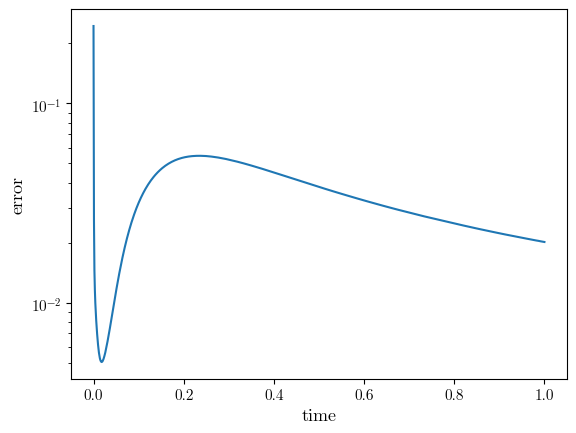

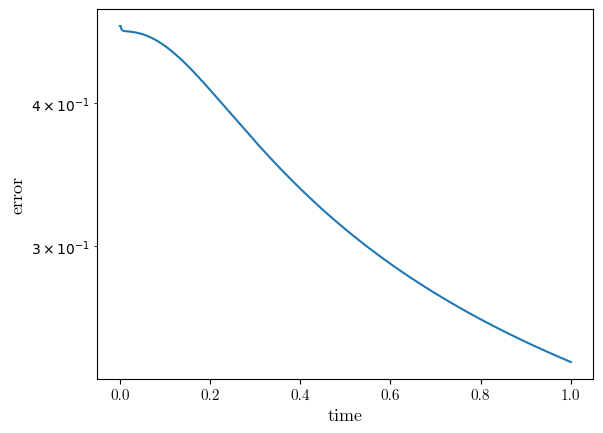

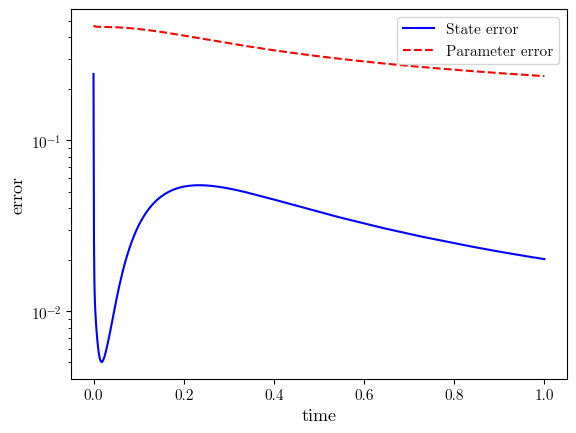

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

0.003/

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

... (23 outputs left out)

0.9960000000000008/

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

0.9970000000000008/noiselevel: 0.05


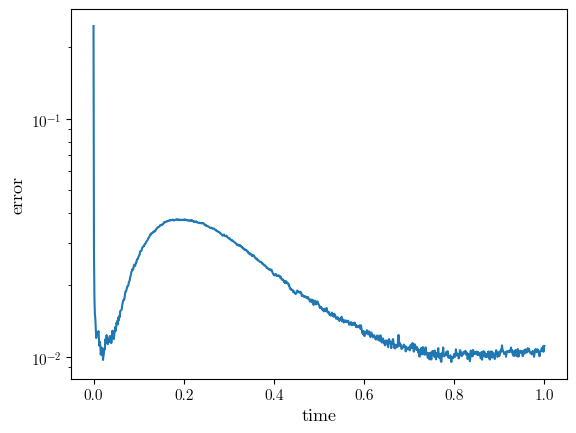

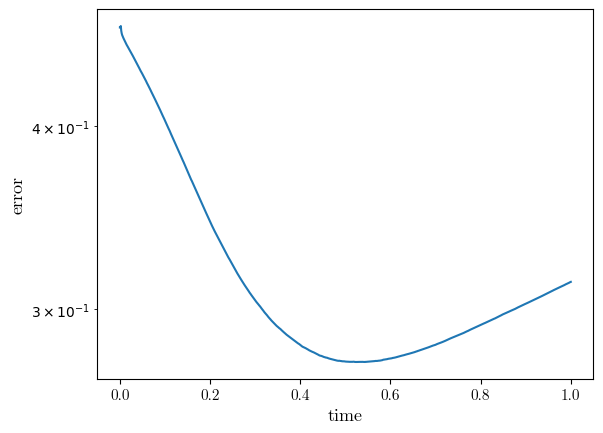

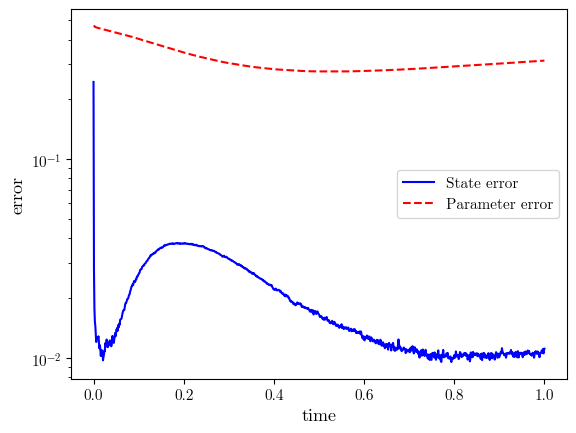

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

In [ ]:
# main MRAS/time-stepping loop: solves for u and q jointly on space X
X = FESpace([Ufes,Qfes])
u, q = X.TrialFunction()
v, s = X.TestFunction()
gf = GridFunction(X)
# MRAS
z, z_old = GridFunction(Ufes),GridFunction(Ufes)
for noise_level in [0,0.05]:  #different noise levels
    counter = 1  #check
    # Initial u and q
    gfu.Set(coef_0)
    r = (x-.5)**2 + (y-.5)**2
    radius = .42
    gfq.Set(IfPos(radius**2 - r,1,0))
    #initial error computation
    error_u = [norm(gfu-u_exact[0],mesh)]
    error_q = [norm(gfq-q_exact,mesh)]
    saved_gfu = []
    saved_gfu.append(gfu.vec.FV().NumPy().copy())
    saved_gfq = []
    saved_gfq.append(gfq.vec.FV().NumPy().copy())
    series_gfu = []
    series_gfu.append(gfu.vec.FV().NumPy().copy())
    series_gfq = []
    series_gfq.append(gfq.vec.FV().NumPy().copy())
    t.Set(0)
    z_old.Set(CF(0))
    while t < tend-2*dt:
        print("\r",t.Get(),"/",sep="",end="")
        # Get updated data z and g and compute time derivative zt
        z_old.vec.data = z.vec.Copy()
        if counter==4: z =  add_noise_draw(u_exact[counter],noise_level,Ufes,mesh, 20)
        else: z =  add_noise(u_exact[counter],noise_level,Ufes,mesh, 20)
        zt = GridFunction(Ufes)
        zt.vec.data = z.vec.Copy()
        zt.vec.data -= z_old.vec.Copy()
        zt.vec.data /= dt
        coef_f = GridFunction(Ufes)
        coef_f = to_gridfunc(np_random[counter],Ufes, mesh)
        g = GridFunction(coef_f.space)
        g.vec.data = coef_f.vec.Copy() # gaussian

        #joint solve
        a = BilinearForm(X)
        res = LinearForm(X)
        
        a += u * v * dx 
        a += dt * Grad(u) * Grad(v) * dx
        a += dt * q * Grad(z) * Grad(v) * dx
        a += q * s * dx
        
        res += gfu * v * dx
        res += dt * coef_f * v * dx
        res += dt * Grad(z) * Grad(v) * dx
        res += gfq * s * dx
        res += dt * Grad(z_old)*(Grad(gfu)-Grad(z_old)) * s * dx#(Grad(z)[0] * (Grad(gfu)[0] - Grad(z)[0]) + Grad(z)[1] * (Grad(gfu)[1] - Grad(z)[1])) * s * dx
        
        a.Assemble()
        res.Assemble()

        c = Preconditioner(a,"local")   #<- Jacobi preconditioner
        c.Update()
        solvers.BVP(bf=a, lf=res, gf=gf, pre=c, print = False)
        gfu.Set(gf.components[0])
        error_q.append(norm(gfq-q_exact,mesh))
        if counter%100==0: saved_gfq.append(gfq.vec.FV().NumPy().copy())
        gfq.Set(gf.components[1])         
        error_u.append(norm(gfu-u_exact[counter],mesh))
        if counter%100==0: saved_gfu.append(gfu.vec.FV().NumPy().copy())
        t += dt    # Update time
        counter += 1
        if counter in [1,5,10,25,50,75,100,200, 500,1500,5000, tsteps-2]: #COUNTER DOES NOT REACH tsteps
            Draw(gfu, min = umin, max = umax)
            series_gfu.append(gfu.vec.FV().NumPy().copy())
            Draw(gfq, min = qmin, max = qmax)
            series_gfq.append(gfq.vec.FV().NumPy().copy())
    print("noiselevel: "+str(noise_level))
    plot_error(tstart,tend,tsteps,noise_level,error_u,error_q)
    draw_gridfuncs (tsteps,u_exact,q_exact,gfu,gfq,mesh,umin, umax, qmin, qmax)
    save (mesh,noise_level,saved_gfu,saved_gfq)
    stacked_u_new = np.stack(series_gfu, axis=0)  # shape (n_timesteps, n_dofs)
    if noise_level != 0: np.save("u_series_over_time_noise"+str(noise_level)+".npy", stacked_u_new)
    else: np.save("u_series_over_time_withoutnoise"+str(noise_level)+".npy", stacked_u_new)
    stacked_q_new = np.stack(series_gfq, axis=0)  # shape (n_timesteps, n_dofs)
    if noise_level !=0: np.save("q_series_over_time_noise"+str(noise_level)+".npy", stacked_q_new)
    else: np.save("q_series_over_time_withoutnoise"+str(noise_level)+".npy", stacked_q_new)

In [7]:
Draw(u_exact[tsteps-1]-gfu,mesh, settings={"Objects": {"Wireframe": False}})
Draw(q_exact-gfq,mesh, settings={"Objects": {"Wireframe": False}})

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

BaseWebGuiScene

In [8]:
Draw(gfq,mesh)

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

BaseWebGuiScene